# UCS420 Lab Assignment 8 — NLP using Python-II
(Feature extraction from text, sentiment analysis and text generation)

In [ ]:
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
            "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

---
## Q1. Text Preprocessing & Word Frequency
Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.).
1. Convert text to lowercase and remove punctuation using re.
2. Tokenize the text into words and sentences.
3. Split using split() and word_tokenize() and compare how Python split and NLTK's word_tokenize() differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribution (excluding stopwords).

In [3]:
import re
import string
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

# Step 1: Write a unique paragraph about a favorite topic
paragraph = """Artificial intelligence is transforming the way we interact with technology every day. 
Machine learning algorithms can now recognize faces, translate languages, and even drive cars autonomously. 
Deep learning, a subset of machine learning, uses neural networks with multiple layers to learn complex patterns. 
Natural language processing enables computers to understand and generate human language with remarkable accuracy. 
The rapid advancement of AI has also raised important ethical questions about privacy and job displacement. 
Despite these concerns, AI continues to offer incredible opportunities in healthcare, education, and scientific research."""

print("Original Paragraph:")
print(paragraph)
print()

# Step 2: Convert to lowercase and remove punctuation using re
text_lower = paragraph.lower()
text_clean = re.sub(r'[^\w\s]', '', text_lower)  # remove punctuation
print("Cleaned Text (lowercase, no punctuation):")
print(text_clean)
print()

# Step 3: Tokenize into words and sentences
sentences = sent_tokenize(paragraph)
print(f"Number of sentences: {len(sentences)}")
for i, s in enumerate(sentences):
    print(f"  Sentence {i+1}: {s}")
print()

# Step 4: Compare split() vs word_tokenize()
tokens_split = text_clean.split()
tokens_nltk = word_tokenize(text_clean)

print(f"Tokens using split() [{len(tokens_split)}]: {tokens_split}")
print()
print(f"Tokens using word_tokenize() [{len(tokens_nltk)}]: {tokens_nltk}")
print()

# Comparison
print("Comparison:")
print(f"  split() gives {len(tokens_split)} tokens")
print(f"  word_tokenize() gives {len(tokens_nltk)} tokens")
print("  split() splits only on whitespace, while word_tokenize() uses language-aware rules")
print("  For this cleaned text (no punctuation), both produce similar results.")
print("  The difference becomes clear with contractions: e.g., \"can't\" -> split gives 1 token, word_tokenize gives 2 tokens (ca, n't).")
print()

# Step 5: Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_tokens = [w for w in tokens_nltk if w not in stop_words]
print(f"Tokens after stopword removal [{len(filtered_tokens)}]: {filtered_tokens}")
print()

# Step 6: Word frequency distribution (excluding stopwords)
freq_dist = Counter(filtered_tokens)
print("Word Frequency Distribution (excluding stopwords):")
for word, count in freq_dist.most_common():
    print(f"  {word}: {count}")

Original Paragraph:
Artificial intelligence is transforming the way we interact with technology every day. 
Machine learning algorithms can now recognize faces, translate languages, and even drive cars autonomously. 
Deep learning, a subset of machine learning, uses neural networks with multiple layers to learn complex patterns. 
Natural language processing enables computers to understand and generate human language with remarkable accuracy. 
The rapid advancement of AI has also raised important ethical questions about privacy and job displacement. 
Despite these concerns, AI continues to offer incredible opportunities in healthcare, education, and scientific research.

Cleaned Text (lowercase, no punctuation):
artificial intelligence is transforming the way we interact with technology every day 
machine learning algorithms can now recognize faces translate languages and even drive cars autonomously 
deep learning a subset of machine learning uses neural networks with multiple layers t

---
## Q2. Stemming vs Lemmatization
Using the same paragraph from Q1:
1. Extract all words with only alphabets using re.findall()
2. Remove stop words using NLTK's stopword list
3. Perform stemming with PorterStemmer
4. Perform lemmatization with WordNetLemmatizer
5. Compare the stemmed and lemmatized outputs and explain when you'd prefer one over the other.

In [4]:
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

# Step 1: Extract all words with only alphabets using re.findall()
alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())
print(f"Words with only alphabets [{len(alpha_words)}]: {alpha_words}")
print()

# Step 2: Remove stop words
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in alpha_words if w not in stop_words]
print(f"After stopword removal [{len(filtered_words)}]: {filtered_words}")
print()

# Step 3: Perform stemming with PorterStemmer
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]

# Step 4: Perform lemmatization with WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

# Helper function to map POS tags to WordNet POS
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('N'):
        return 'n'
    elif tag.startswith('R'):
        return 'r'
    else:
        return 'n'

tagged_words = pos_tag(filtered_words)
lemmatized_words = [lemmatizer.lemmatize(w, pos=get_wordnet_pos(tag)) for w, tag in tagged_words]

# Step 5: Compare stemmed and lemmatized outputs
comparison_df = pd.DataFrame({
    'Original': filtered_words,
    'Stemmed': stemmed_words,
    'Lemmatized': lemmatized_words
})

print("Full Comparison Table:")
print(comparison_df.to_string(index=False))
print()

# Show only where outputs differ
diff_df = comparison_df[comparison_df['Stemmed'] != comparison_df['Lemmatized']]
print("Words where Stemmed != Lemmatized:")
print(diff_df.to_string(index=False))
print()

print("Observation:")
print("  - Stemming is faster and more aggressive — it chops off suffixes without understanding context.")
print("  - Lemmatization produces valid dictionary words using POS tags.")
print("  - Prefer stemming when speed matters and exact words are not critical (e.g., search engines).")
print("  - Prefer lemmatization when meaningful, readable words are needed (e.g., chatbots, text generation).")

Words with only alphabets [88]: ['artificial', 'intelligence', 'is', 'transforming', 'the', 'way', 'we', 'interact', 'with', 'technology', 'every', 'day', 'machine', 'learning', 'algorithms', 'can', 'now', 'recognize', 'faces', 'translate', 'languages', 'and', 'even', 'drive', 'cars', 'autonomously', 'deep', 'learning', 'a', 'subset', 'of', 'machine', 'learning', 'uses', 'neural', 'networks', 'with', 'multiple', 'layers', 'to', 'learn', 'complex', 'patterns', 'natural', 'language', 'processing', 'enables', 'computers', 'to', 'understand', 'and', 'generate', 'human', 'language', 'with', 'remarkable', 'accuracy', 'the', 'rapid', 'advancement', 'of', 'ai', 'has', 'also', 'raised', 'important', 'ethical', 'questions', 'about', 'privacy', 'and', 'job', 'displacement', 'despite', 'these', 'concerns', 'ai', 'continues', 'to', 'offer', 'incredible', 'opportunities', 'in', 'healthcare', 'education', 'and', 'scientific', 'research']

After stopword removal [65]: ['artificial', 'intelligence', 't

---
## Q3. Bag of Words & TF-IDF
Choose 3 short texts of your own (e.g., different news headlines, product reviews).
1. Use CountVectorizer to generate the Bag of Words representation.
2. Use TfidfVectorizer to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd
import numpy as np

# 3 short texts (product reviews)
texts = [
    "The new smartphone has an amazing camera and excellent battery life. The display is vibrant and the performance is smooth.",
    "This laptop is lightweight and perfect for students. The keyboard feels great and the battery lasts all day long.",
    "The wireless earbuds have superb sound quality and noise cancellation. They are comfortable to wear for hours."
]

print("Texts:")
for i, t in enumerate(texts):
    print(f"  Text {i+1}: {t}")
print()

# Step 1: Bag of Words using CountVectorizer
count_vec = CountVectorizer()
bow_matrix = count_vec.fit_transform(texts)

bow_df = pd.DataFrame(bow_matrix.toarray(), columns=count_vec.get_feature_names_out(),
                      index=[f'Text {i+1}' for i in range(len(texts))])
print("Bag of Words Representation:")
print(bow_df.to_string())
print()

# Step 2: TF-IDF using TfidfVectorizer
tfidf_vec = TfidfVectorizer()
tfidf_matrix = tfidf_vec.fit_transform(texts)

tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vec.get_feature_names_out(),
                        index=[f'Text {i+1}' for i in range(len(texts))])
print("TF-IDF Representation:")
print(tfidf_df.round(4).to_string())
print()

# Step 3: Top 3 keywords from each text using TF-IDF
print("Top 3 Keywords per Text (TF-IDF):")
feature_names = tfidf_vec.get_feature_names_out()
for i in range(len(texts)):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]
    top_keywords = [(feature_names[j], round(scores[j], 4)) for j in top_indices]
    print(f"  Text {i+1}: {top_keywords}")

print()
print("Interpretation:")
print("  TF-IDF highlights words that are unique and important to each text.")
print("  Common words across all texts get lower scores, while distinctive words get higher scores.")

Texts:
  Text 1: The new smartphone has an amazing camera and excellent battery life. The display is vibrant and the performance is smooth.
  Text 2: This laptop is lightweight and perfect for students. The keyboard feels great and the battery lasts all day long.
  Text 3: The wireless earbuds have superb sound quality and noise cancellation. They are comfortable to wear for hours.

Bag of Words Representation:
        all  amazing  an  and  are  battery  camera  cancellation  comfortable  day  display  earbuds  excellent  feels  for  great  has  have  hours  is  keyboard  laptop  lasts  life  lightweight  long  new  noise  perfect  performance  quality  smartphone  smooth  sound  students  superb  the  they  this  to  vibrant  wear  wireless
Text 1    0        1   1    2    0        1       1             0            0    0        1        0          1      0    0      0    1     0      0   2         0       0      0     1            0     0    1      0        0            1        0 

---
## Q4. Text Similarity
Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain).
1. Preprocess and tokenize both texts.
2. Calculate:
   a. Jaccard Similarity using sets
   b. Cosine Similarity using TfidfVectorizer + cosine_similarity()
   c. Analyze which similarity metric gives better insights in your case.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import re

# Two short texts about different technologies
text1 = """Artificial intelligence is a branch of computer science that aims to create intelligent machines.
AI systems can learn from data, recognize patterns, and make decisions with minimal human intervention.
Machine learning and deep learning are key subfields of AI that use neural networks.
AI is widely used in healthcare, finance, autonomous vehicles, and natural language processing.
The technology continues to evolve rapidly, raising both excitement and ethical concerns."""

text2 = """Blockchain is a decentralized digital ledger technology that records transactions across multiple computers.
It ensures data integrity through cryptographic hashing and consensus mechanisms.
Blockchain is the foundation of cryptocurrencies like Bitcoin and Ethereum.
Smart contracts on blockchain platforms automate agreements without intermediaries.
The technology has applications beyond finance, including supply chain management and voting systems."""

print("Text 1 (AI):")
print(text1)
print()
print("Text 2 (Blockchain):")
print(text2)
print()

# Step 1: Preprocess and tokenize
stop_words = set(stopwords.words('english'))

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)  # remove punctuation
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words and t.isalpha()]
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print(f"Tokens Text 1 [{len(tokens1)}]: {tokens1}")
print(f"Tokens Text 2 [{len(tokens2)}]: {tokens2}")
print()

# Step 2a: Jaccard Similarity
set1 = set(tokens1)
set2 = set(tokens2)
intersection = set1 & set2
union = set1 | set2
jaccard_sim = len(intersection) / len(union)

print(f"Common words (intersection): {intersection}")
print(f"Jaccard Similarity: {jaccard_sim:.4f}")
print()

# Step 2b: Cosine Similarity
tfidf_vec = TfidfVectorizer()
tfidf_matrix = tfidf_vec.fit_transform([text1, text2])
cos_sim = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print(f"Cosine Similarity: {cos_sim:.4f}")
print()

# Step 2c: Analysis
print("Analysis:")
print(f"  Jaccard Similarity = {jaccard_sim:.4f}")
print(f"  Cosine Similarity  = {cos_sim:.4f}")
print()
print("  Jaccard Similarity only checks word overlap (presence/absence), ignoring frequency and importance.")
print("  Cosine Similarity uses TF-IDF vectors, so it considers both word frequency and importance.")
print("  Cosine Similarity gives better insights here because it captures the semantic weight of words,")
print("  not just whether they appear in both texts. It correctly shows the texts are related (both about technology)")
print("  but are discussing different subjects.")

Text 1 (AI):
Artificial intelligence is a branch of computer science that aims to create intelligent machines.
AI systems can learn from data, recognize patterns, and make decisions with minimal human intervention.
Machine learning and deep learning are key subfields of AI that use neural networks.
AI is widely used in healthcare, finance, autonomous vehicles, and natural language processing.
The technology continues to evolve rapidly, raising both excitement and ethical concerns.

Text 2 (Blockchain):
Blockchain is a decentralized digital ledger technology that records transactions across multiple computers.
It ensures data integrity through cryptographic hashing and consensus mechanisms.
Blockchain is the foundation of cryptocurrencies like Bitcoin and Ethereum.
Smart contracts on blockchain platforms automate agreements without intermediaries.
The technology has applications beyond finance, including supply chain management and voting systems.

Tokens Text 1 [48]: ['artificial', 'in

---
## Q5. Sentiment Analysis
Write a short review for a product or service.
1. Use TextBlob or VADER to find polarity & subjectivity for each review.
2. Classify reviews into Positive / Negative / Neutral.
3. Create a word cloud using the wordcloud library for all positive reviews.

VADER Sentiment Scores:
                                                                   Review  Positive  Negative  Neutral  Compound
This phone is absolutely amazing! The camera quality is superb and the...     0.377     0.000    0.623    0.8585
Terrible customer service. I waited for two hours and nobody helped me...     0.000     0.375    0.625   -0.7645
The food was okay, nothing special. It was an average experience overa...     0.134     0.159    0.706   -0.0920
I love this laptop! It's fast, lightweight, and the display is stunnin...     0.513     0.000    0.487    0.9115
The hotel room was dirty and the staff was rude. Worst experience of m...     0.000     0.455    0.545   -0.8750
Great value for money. The product works well and shipping was fast. H...     0.539     0.000    0.461    0.8930
         The movie was boring and predictable. I wouldn't watch it again.     0.000     0.204    0.796   -0.3182
Excellent quality headphones with crystal clear sound. Comfortable for..

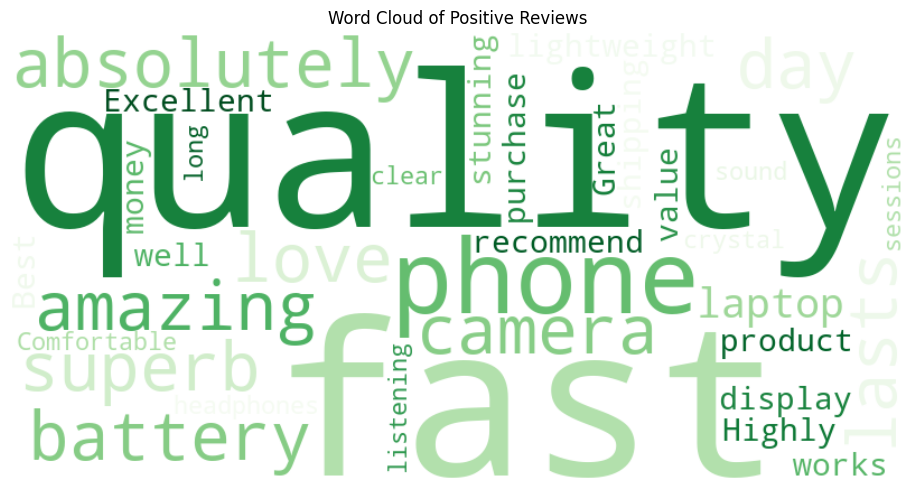

In [9]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import pandas as pd

# Short reviews for products/services
reviews = [
    "This phone is absolutely amazing! The camera quality is superb and the battery lasts all day.",
    "Terrible customer service. I waited for two hours and nobody helped me. Very disappointing.",
    "The food was okay, nothing special. It was an average experience overall.",
    "I love this laptop! It's fast, lightweight, and the display is stunning. Best purchase ever!",
    "The hotel room was dirty and the staff was rude. Worst experience of my life.",
    "Great value for money. The product works well and shipping was fast. Highly recommend!",
    "The movie was boring and predictable. I wouldn't watch it again.",
    "Excellent quality headphones with crystal clear sound. Comfortable for long listening sessions."
]

# Step 1: Use VADER to find polarity for each review
sia = SentimentIntensityAnalyzer()

results = []
for review in reviews:
    scores = sia.polarity_scores(review)
    results.append({
        'Review': review[:70] + '...' if len(review) > 70 else review,
        'Positive': round(scores['pos'], 4),
        'Negative': round(scores['neg'], 4),
        'Neutral': round(scores['neu'], 4),
        'Compound': round(scores['compound'], 4)
    })

results_df = pd.DataFrame(results)
print("VADER Sentiment Scores:")
print(results_df.to_string(index=False))
print()

# Step 2: Classify reviews into Positive / Negative / Neutral
classifications = []
positive_reviews = []

for i, review in enumerate(reviews):
    compound = sia.polarity_scores(review)['compound']
    if compound >= 0.05:
        label = 'Positive'
        positive_reviews.append(review)
    elif compound <= -0.05:
        label = 'Negative'
    else:
        label = 'Neutral'
    classifications.append({'Review': review[:70] + '...' if len(review) > 70 else review,
                            'Compound': round(compound, 4),
                            'Classification': label})

class_df = pd.DataFrame(classifications)
print("Review Classifications:")
print(class_df.to_string(index=False))
print()

# Step 3: Word cloud for positive reviews
positive_text = ' '.join(positive_reviews)
wordcloud = WordCloud(width=800, height=400, background_color='white',
                      colormap='Greens').generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Positive Reviews')
plt.tight_layout()
plt.show()

---
## Q6. Text Generation with LSTM
Choose your own paragraph (~100 words) as training data.
1. Tokenize text using Tokenizer() from keras.preprocessing.text
2. Create input sequences and build a simple LSTM or Dense model
3. Train the model and generate 2–3 new lines of text starting from any seed word you provide.

In [8]:
import numpy as np
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

# Step 1: Training paragraph (~100 words)
training_text = """Artificial intelligence is transforming the world at an unprecedented pace.
Machine learning algorithms are becoming more powerful every year.
Deep learning models can now understand images and generate realistic text.
Neural networks are inspired by the human brain and can learn complex patterns.
Natural language processing allows computers to read and understand human language.
AI is being used in healthcare to diagnose diseases and recommend treatments.
Self driving cars use computer vision and sensors to navigate roads safely.
The future of technology depends on how responsibly we develop artificial intelligence.
Researchers are working hard to make AI systems fair transparent and beneficial for everyone."""

print("Training Text:")
print(training_text)
print()

# Step 2: Tokenize text using Tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1

print(f"Total unique words: {total_words - 1}")
print(f"Word index (first 20): {dict(list(tokenizer.word_index.items())[:20])}")
print()

# Step 3: Create input sequences
input_sequences = []
for line in training_text.split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram = token_list[:i+1]
        input_sequences.append(n_gram)

# Pad sequences
max_seq_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre')

# Split into features (X) and labels (y)
X = input_sequences[:, :-1]
y = input_sequences[:, -1]
y = to_categorical(y, num_classes=total_words)

print(f"Number of input sequences: {len(X)}")
print(f"Max sequence length: {max_seq_len}")
print()

# Step 4: Build LSTM model
model = Sequential([
    Embedding(total_words, 64, input_length=max_seq_len - 1),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()
print()

# Train the model
print("Training the model...")
history = model.fit(X, y, epochs=200, verbose=0)
print(f"Final training accuracy: {history.history['accuracy'][-1]:.4f}")
print(f"Final training loss: {history.history['loss'][-1]:.4f}")
print()

# Step 5: Generate text from seed words
def generate_text(seed_text, num_words, model, tokenizer, max_seq_len):
    result = seed_text
    for _ in range(num_words):
        token_list = tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences([token_list], maxlen=max_seq_len - 1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
        output_word = ''
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                output_word = word
                break
        result += ' ' + output_word
    return result

# Generate text with different seed words
seed_words = ['artificial', 'machine', 'the future']
print("Generated Text:")
for seed in seed_words:
    generated = generate_text(seed, num_words=10, model=model,
                              tokenizer=tokenizer, max_seq_len=max_seq_len)
    print(f"  Seed: '{seed}' -> {generated}")

Training Text:
Artificial intelligence is transforming the world at an unprecedented pace.
Machine learning algorithms are becoming more powerful every year.
Deep learning models can now understand images and generate realistic text.
Neural networks are inspired by the human brain and can learn complex patterns.
Natural language processing allows computers to read and understand human language.
AI is being used in healthcare to diagnose diseases and recommend treatments.
Self driving cars use computer vision and sensors to navigate roads safely.
The future of technology depends on how responsibly we develop artificial intelligence.
Researchers are working hard to make AI systems fair transparent and beneficial for everyone.

Total unique words: 83
Word index (first 20): {'and': 1, 'to': 2, 'the': 3, 'are': 4, 'artificial': 5, 'intelligence': 6, 'is': 7, 'learning': 8, 'can': 9, 'understand': 10, 'human': 11, 'language': 12, 'ai': 13, 'transforming': 14, 'world': 15, 'at': 16, 'an': 17,

c:\Users\Saket Gatyan\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Training the model...
Final training accuracy: 1.0000
Final training loss: 0.1741

Generated Text:
  Seed: 'artificial' -> artificial intelligence is transforming the world at an unprecedented pace pace
  Seed: 'machine' -> machine learning algorithms are becoming more powerful every year year complex
  Seed: 'the future' -> the future of technology depends on how responsibly we develop artificial intelligence
